In [752]:
# %config InlineBackend.figure_format = 'png'

In [753]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [754]:
aid_df = pd.read_excel(
  'greenbook/us_foreignaid_greenbook.xlsx',
  skiprows=6,
  header=0,
)

In [755]:
aid_df = aid_df.drop(columns='Region')

In [756]:
aid_df.head(2)

,Fiscal Year,Country,Assistance Category,Publication Row,Funding Agency,Funding Account Name,Obligations (Historical Dollars),Obligations (Constant Dollars)
0,1946.0,Egypt,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - US Surplus Property,9300000,101307190
1,1946.0,Egypt,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - UN Relif and Rehab Agency (UNRRA),300000,3267974


In [757]:
rename_map = {
  'Obligations (Historical Dollars)': 'total_hist',
  'Obligations (Constant Dollars)': 'total_const',
  'Fiscal Year': 'year',
  'Country': 'country',
}
aid_df = aid_df.rename(columns=rename_map)

In [758]:
aid_df['year'] = aid_df['year'].astype(int)

In [759]:
aid_df

,year,country,Assistance Category,Publication Row,Funding Agency,Funding Account Name,total_hist,total_const
0,1946,Egypt,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - US Surplus Property,9300000,101307190
1,1946,Egypt,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - UN Relif and Rehab Agency (UNRRA),300000,3267974
2,1946,Iran,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - US Surplus Property,3300000,35947712
3,1946,Lebanon,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - US Surplus Property,1600000,17429194
4,1946,Saudi Arabia,Economic,Inactive Programs,Department of the Treasury,INACTIVE - Lend Lease Silver,2400000,26143791
...,...,...,...,...,...,...,...,...
74997,2020,World (not specified),Military,Foreign Military Financing,Department of State,Foreign Military Financing Program,3969166,3969166
74998,2020,World (not specified),Military,International Military Education and Training,Department of State,International Military Education and Training,3851885,3851885
74999,2020,World (not specified),Military,Peace Keeping Operations,Department of State,Peace Keeping Operations,103022000,103022000
75000,2020,World (not specified),Military,Other Military Assistance,Department of Defense,"Operation and Maintenance, Air Force",1500000,1500000


In [760]:
exclude_countries = [
  'World (not specified)',
  'Asia (not specified)',
  'Oceania (not specified)',
  'Latin America & Caribbean (not specified)',
  'Sub-Saharan Africa (not specified)',
  'Central America (not specified)',
  'Western Europe (not specified)',
  'Southern Africa (not specified)',
  'Caribbean (not specified)',
  'Middle East & North Africa (not specified)',
  'East Africa (not specified)',
  'Eurasia (not specified)',
  'Eastern Europe (not specified)',
  'West Africa (not specified)',
  # Permanent members
  'China (Hong Kong)',
  'China (P.R.C.)',
  'United Kingdom',
  'France',
  'Russia',
]

In [761]:
aid_df = aid_df[~aid_df['country'].isin(exclude_countries)]

In [791]:
name_map = {
  'Congo (Kinshasa)': 'Democratic Republic of the Congo',
  'Congo (Brazzaville)': 'Republic of the Congo',
  'Korea, North': 'North Korea',
  'Korea, South': 'South Korea',
  'Micronesia (Federated States of)': 'Federated States of Micronesia',
  'China (Taiwan)': 'Taiwan',
  'Gambia, The': 'Gambia',
  "Cote d'Ivoire": "Côte d'Ivoire",
  "Serbia and Montenegro, Former": "Yugoslavia",
  "Turkey": 'Türkiye',
  "United Arab Republic": "Egypt",
  'Trinidad & Tobago': 'Trinidad and Tobago',
  'Congo': 'Republic of the Congo',
  'Vietnam': 'Viet Nam',
  'Bosnia & Herzegovina': 'Bosnia and Herzegovina',
  'St. Vincent and Grenadines': 'Saint Vincent and the Grenadines',
  'Bahamas, The': 'Bahamas',
}
aid_df['country'] = aid_df['country'].apply(lambda x: name_map[x] if x in name_map else x)

Special case: germany pre-1990

In [792]:
aid_df

,year,country,Assistance Category,Publication Row,Funding Agency,Funding Account Name,total_hist,total_const,total_const_m
0,1946,Egypt,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - US Surplus Property,9300000,101307190,101.307190
1,1946,Egypt,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - UN Relif and Rehab Agency (UNRRA),300000,3267974,3.267974
2,1946,Iran,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - US Surplus Property,3300000,35947712,35.947712
3,1946,Lebanon,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - US Surplus Property,1600000,17429194,17.429194
4,1946,Saudi Arabia,Economic,Inactive Programs,Department of the Treasury,INACTIVE - Lend Lease Silver,2400000,26143791,26.143791
...,...,...,...,...,...,...,...,...,...
74939,2020,Canada,Economic,Department of Energy,Department of Energy,"Defense Nuclear Nonproliferation, Energy",82000,82000,0.082000
74940,2020,Canada,Economic,Department of Interior,Department of the Interior,"Neotropical Migratory Bird Conservation, U.S. ...",312304,312304,0.312304
74941,2020,Canada,Economic,Department of Interior,Department of the Interior,"U.S. Fish and Wildlife Service, Federal Aid to...",18768153,18768153,18.768153
74942,2020,Canada,Economic,Department of Interior,Department of the Interior,"U.S. Fish and Wildlife Service, North American...",15943803,15943803,15.943803


In [793]:
aid_df['country'].value_counts()

country
Philippines    969
Peru           940
Guatemala      927
Colombia       874
Kenya          872
              ... 
Sweden          26
New Zealand     24
Kiribati        23
Brunei          15
Switzerland     14
Name: count, Length: 185, dtype: int64

In [794]:
aid_df['country'].value_counts().to_frame().to_csv('aid_country_counts.csv')

In [795]:
aid_df['total_const_m'] = aid_df['total_const'] / 1_000_000

In [796]:
panel_df = aid_df.groupby(['country','year'])['total_const_m'].sum().to_frame().reset_index()
panel_df

,country,year,total_const_m
0,Afghanistan,1950,0.008795
1,Afghanistan,1951,0.835422
2,Afghanistan,1952,2.409639
3,Afghanistan,1953,17.350157
4,Afghanistan,1954,19.485581
...,...,...,...
9170,Zimbabwe,2016,281.090015
9171,Zimbabwe,2017,228.174108
9172,Zimbabwe,2018,236.395167
9173,Zimbabwe,2019,320.657671


In [797]:
panel_df.to_csv('aid_panel.csv', index=False)

In [798]:
panel_df[panel_df['country'].str.contains('Form')]

,country,year,total_const_m


## Yemen: 1990-1991

In [770]:
yem_df = aid_df[aid_df['country'].str.contains('Yemen')].copy()

In [771]:
yem_df

,year,country,Assistance Category,Publication Row,Funding Agency,Funding Account Name,total_hist,total_const,total_const_m
2635,1959,Yemen,Economic,Other USAID Assistance,U.S. Agency for International Development,INACTIVE - USAID Grants,300000,2084781,2.084781
2636,1959,Yemen,Economic,Public Law 480 Title II Grants,Department of Agriculture,Public Law 480 Title II Grants,4800000,33356498,33.356498
3045,1960,Yemen,Economic,Other USAID Assistance,U.S. Agency for International Development,INACTIVE - USAID Grants,3000000,20562029,20.562029
3046,1960,Yemen,Economic,Public Law 480 Title II Grants,Department of Agriculture,Public Law 480 Title II Grants,2600000,17820425,17.820425
3468,1961,Yemen,Economic,Other USAID Assistance,U.S. Agency for International Development,INACTIVE - USAID Grants,4000000,27063599,27.063599
...,...,...,...,...,...,...,...,...,...
72908,2020,Yemen,Economic,Global Health Programs,Department of State,Global Health Programs,6234853,6234853,6.234853
72909,2020,Yemen,Economic,Narcotics Control,Department of State,International Narcotics Control and Law Enforc...,166182,166182,0.166182
72910,2020,Yemen,Economic,Refugee and Migration,Department of State,"Migration and Refugee Assistance, Department o...",53280000,53280000,53.280000
72911,2020,Yemen,Economic,"Nonproliferation, Anti-Terrorism, Demining & R...",Department of State,"Nonproliferation, Anti-Terrorism, Demining and...",22471652,22471652,22.471652


In [772]:
yem_late_df = yem_df[
  (yem_df['year'] >= 1989)
  & (yem_df['year'] <= 1992)
].copy()

In [773]:
yem_late_df

,year,country,Assistance Category,Publication Row,Funding Agency,Funding Account Name,total_hist,total_const,total_const_m
17753,1989,Yemen,Economic,Other USAID Assistance,U.S. Agency for International Development,INACTIVE - USAID Grants,23498000,43741623,43.741623
17754,1989,Yemen,Economic,Public Law 480 Title II Grants,Department of Agriculture,Public Law 480 Title II Grants,353000,657111,0.657111
17755,1989,Yemen,Economic,Other USDA Assistance,Department of Agriculture,Public Law 480 Title I Food for Progress Credi...,10000000,18615041,18.615041
17756,1989,Yemen,Economic,Peace Corps,Peace Corps,Peace Corps,1408000,2620998,2.620998
17757,1989,Yemen,Military,International Military Education and Training,Department of State,International Military Education and Training,1012000,1883842,1.883842
18325,1990,Yemen,Economic,Other USAID Assistance,U.S. Agency for International Development,INACTIVE - USAID Grants,22535000,40465075,40.465075
18326,1990,Yemen,Economic,Other USDA Assistance,Department of Agriculture,Public Law 480 Title I Food for Progress Credi...,20000000,35913090,35.913090
18327,1990,Yemen,Economic,Peace Corps,Peace Corps,Peace Corps,1141000,2048842,2.048842
18328,1990,Yemen,Military,International Military Education and Training,Department of State,International Military Education and Training,595000,1068414,1.068414
18989,1991,Yemen,Economic,Other USAID Assistance,U.S. Agency for International Development,INACTIVE - USAID Grants,2960000,5132651,5.132651


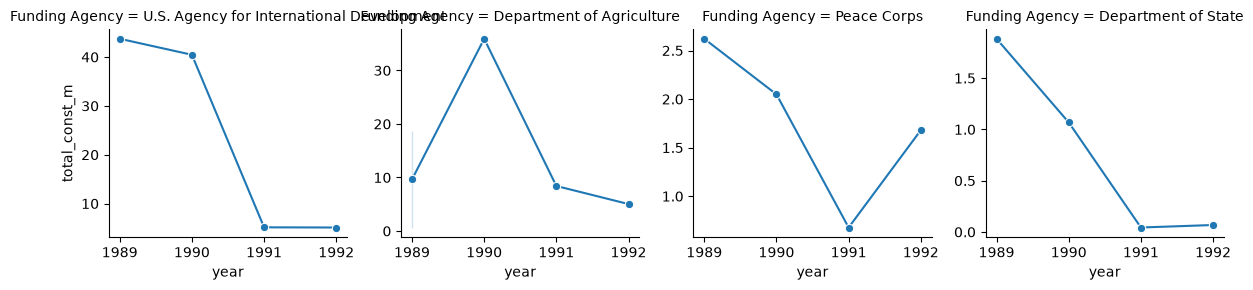

In [774]:
g = sns.FacetGrid(
  data=yem_late_df,
  col='Funding Agency',
  sharey=False,
)
g.map(
  sns.lineplot, "year", "total_const_m", marker='o'
)
# sns.lineplot(
#   x='Fiscal Year', y='total_const',
#   hue='Funding Agency',
#   data=yem_late_df,
#   marker='o',
# )
plt.show()

## Sum to Yearly Totals

In [775]:
yem_yearly_df = (
  yem_late_df
    .groupby(['year','Assistance Category'])['total_const_m']
    .sum()
  .reset_index()
)

In [776]:
yem_mil_df = yem_yearly_df[yem_yearly_df['Assistance Category'] == 'Military'].copy()
yem_mil_df

,year,Assistance Category,total_const_m
1,1989,Military,1.883842
3,1990,Military,1.068414
5,1991,Military,0.043350


In [777]:
yem_92_df = pd.DataFrame({
  'year': [
    1992,
    # 1993,
  ],
  'Assistance Category': [
    'Military',
    # 'Military',
  ],
  'Funding Agency': [
    'Department of State',
    # 'Department of State',
  ],
  'total_const_m': [
    0,
    # 0,
  ],
})

In [778]:
yem_m92_df = pd.concat([yem_mil_df, yem_92_df])

In [779]:
yem_m92_df

,year,Assistance Category,total_const_m,Funding Agency
1,1989,Military,1.883842,NaN
3,1990,Military,1.068414,NaN
5,1991,Military,0.043350,NaN
0,1992,Military,0.000000,Department of State


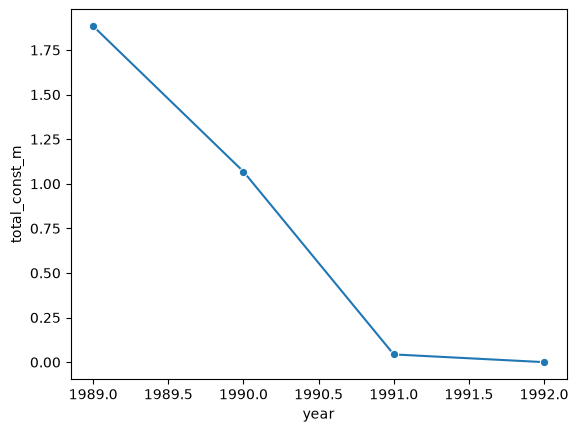

In [780]:
sns.lineplot(
  x='year', y='total_const_m',
  data=yem_m92_df,
  marker='o',
)
plt.show()

Now for both types combined

In [781]:
yem_a92_df = pd.concat([yem_yearly_df, yem_92_df])

In [782]:
yem_a92_df

,year,Assistance Category,total_const_m,Funding Agency
0,1989,Economic,65.634773,NaN
1,1989,Military,1.883842,NaN
2,1990,Economic,78.427007,NaN
3,1990,Military,1.068414,NaN
4,1991,Economic,14.220565,NaN
5,1991,Military,0.043350,NaN
6,1992,Economic,11.879547,NaN
0,1992,Military,0.000000,Department of State


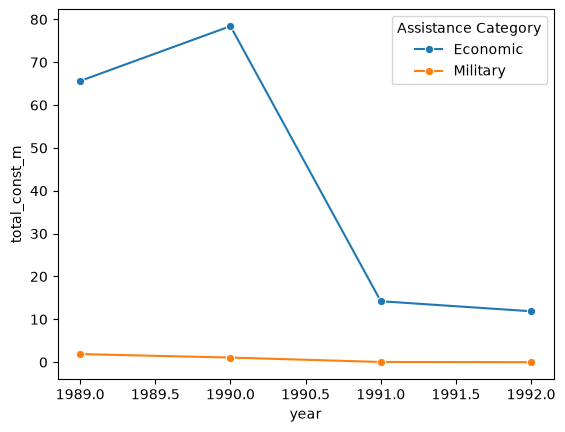

In [783]:
sns.lineplot(
  x='year', y='total_const_m',
  hue='Assistance Category',
  data=yem_a92_df,
  marker='o',
)
plt.show()

And combined

In [784]:
yem_c92_df = yem_a92_df.groupby('year').sum()
yem_c92_df

,Assistance Category,total_const_m,Funding Agency
year,,,
1989,EconomicMilitary,67.518615,
1990,EconomicMilitary,79.495421,
1991,EconomicMilitary,14.263915,
1992,EconomicMilitary,11.879547,Department of State


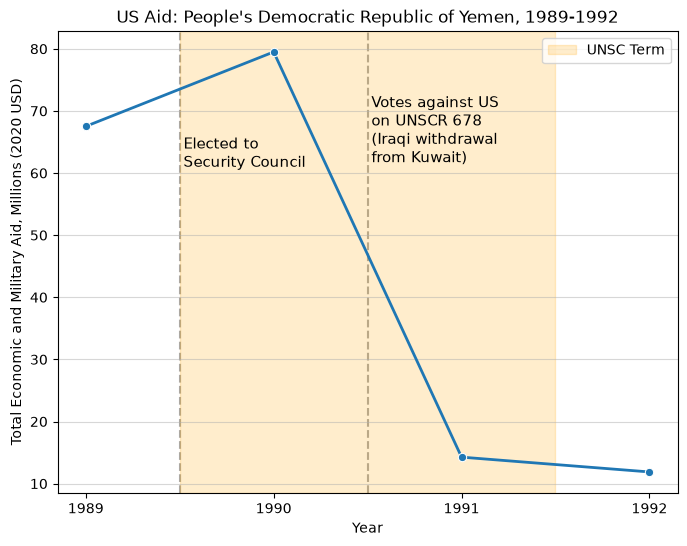

In [789]:
plt.figure(figsize=(8,6));
plt.grid(axis='y', alpha=0.5);
sns.lineplot(
  x='year', y='total_const_m',
  # hue='Assistance Category',
  data=yem_c92_df,
  marker='o',
  zorder=10,
  linewidth=2,
)
plt.title("US Aid: People's Democratic Republic of Yemen, 1989-1992")
# plt.xlim(1989, 1992)
plt.xticks([1989,1990,1991,1992]);
plt.axvline(x=1989.5, linestyle='--', color='darkgray', zorder=1);
plt.axvline(x=1990.5, linestyle='--', color='darkgray', zorder=1);
plt.axvspan(1989.5, 1991.5, color="orange", alpha=0.2, label="UNSC Term");
plt.xlabel('Year');
plt.ylabel('Total Economic and Military Aid, Millions (2020 USD)');
plt.text(
  x=1989.52, y=61, s='Elected to\nSecurity Council', zorder=15,
  size=11,
);
plt.text(
  x=1990.52, y=61.75, s='Votes against US\non UNSCR 678\n(Iraqi withdrawal\nfrom Kuwait)', zorder=15,
  size=11,
);
plt.legend();
# plt.ylim(bottom=0);
plt.show()

## Just SC years

In [594]:
yem_sc_df = yem_df[
  (yem_df['year'] >= 1990)
  & (yem_df['year'] <= 1991)
].copy()

In [595]:
yem_sc_df

,year,country,Assistance Category,Publication Row,Funding Agency,Funding Account Name,total_hist,total_const,total_const_m
18325,1990,Yemen,Economic,Other USAID Assistance,U.S. Agency for International Development,INACTIVE - USAID Grants,22535000,40465075,40.465075
18326,1990,Yemen,Economic,Other USDA Assistance,Department of Agriculture,Public Law 480 Title I Food for Progress Credi...,20000000,35913090,35.913090
18327,1990,Yemen,Economic,Peace Corps,Peace Corps,Peace Corps,1141000,2048842,2.048842
18328,1990,Yemen,Military,International Military Education and Training,Department of State,International Military Education and Training,595000,1068414,1.068414
18989,1991,Yemen,Economic,Other USAID Assistance,U.S. Agency for International Development,INACTIVE - USAID Grants,2960000,5132651,5.132651
18990,1991,Yemen,Economic,Other USDA Assistance,Department of Agriculture,Public Law 480 Title I Food for Progress Credi...,4850000,8409919,8.409919
18991,1991,Yemen,Economic,Peace Corps,Peace Corps,Peace Corps,391000,677995,0.677995
18992,1991,Yemen,Military,International Military Education and Training,Department of State,International Military Education and Training,25000,43350,0.043350


In [596]:
def compute_pct_dec(val_90, val_91):
  return (val_90 - val_91) / val_90

In [597]:
usaid_90 = 40465075
usaid_91 = 5132651
compute_pct_dec(usaid_90, usaid_91)

0.8731584953197294

In [598]:
usda_90 = 35913090
usda_91 = 8409919
compute_pct_dec(usda_90, usda_91)

0.765825803349141

In [599]:
pc_90 = 2048842
pc_91 = 677995
compute_pct_dec(pc_90, pc_91)

0.6690838044124438

In [600]:
mil_90 = 1068414
mil_91 = 43350
compute_pct_dec(mil_90, mil_91)

0.9594258405449573

## Cuba: 1990-1991

In [602]:
cuba_df = aid_df[aid_df['country'].str.contains('Cuba')].copy()

In [603]:
cuba_total_df = cuba_df.groupby('year')['total_const_m'].sum().to_frame().reset_index()
cuba_total_df

,year,total_const_m
0,1946,1.089325
1,1947,0.982318
2,1948,0.896861
3,1951,0.835422
4,1952,5.622490
5,1953,14.984227
6,1954,13.242400
7,1955,16.171693
8,1956,19.140272
9,1957,45.018181


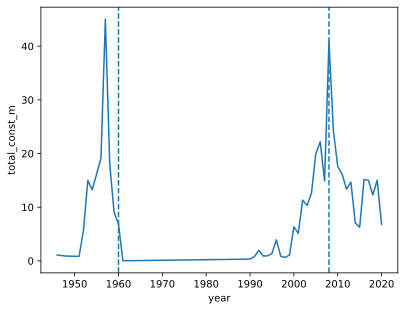

In [605]:
sns.lineplot(
  x='year', y='total_const_m',
  data=cuba_total_df,
)
plt.axvline(1960, ls='--')
plt.axvline(2008, ls='--')
plt.show()

In [606]:
cuba_sc_df = cuba_df[
  (cuba_df['year'] >= 1989)
  & (cuba_df['year'] <= 1992)
].copy()

In [607]:
cuba_sc_df

,year,country,Assistance Category,Publication Row,Funding Agency,Funding Account Name,total_hist,total_const,total_const_m
18630,1990,Cuba,Economic,Other State Assistance,Department of State,"National Endowment for Democracy, Department o...",180000,323218,0.323218
19324,1991,Cuba,Economic,Other State Assistance,Department of State,"National Endowment for Democracy, Department o...",462132,801339,0.801339
20048,1992,Cuba,Economic,Other State Assistance,Department of State,"National Endowment for Democracy, Department o...",1154306,1952810,1.952810


In [608]:
cuba_89_df = pd.DataFrame({
  'year': [1989],
  'Country': ['Cuba'],
  'Assistance Category': ['Economic'],
  'total_const_m': [0],
})

In [609]:
cuba_i89_df = pd.concat([cuba_sc_df, cuba_89_df])

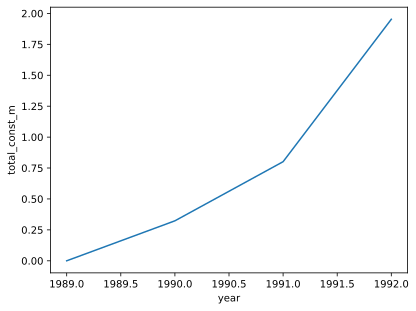

In [611]:
sns.lineplot(
  x='year', y='total_const_m',
  data=cuba_i89_df,
)
plt.show()

## 1968: Paraguay

In [671]:
drc_df = aid_df[aid_df['country'].str.contains('Paraguay')].copy()

In [672]:
drc_df

,year,country,Assistance Category,Publication Row,Funding Agency,Funding Account Name,total_hist,total_const,total_const_m
31,1946,Paraguay,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - Institute of American Affairs (IAA),400000,4357298,4.357298
113,1947,Paraguay,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - Institute of American Affairs (IAA),400000,3929273,3.929273
197,1948,Paraguay,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - Institute of American Affairs (IAA),400000,3587444,3.587444
265,1949,Paraguay,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - Institute of American Affairs (IAA),400000,3472222,3.472222
342,1950,Paraguay,Economic,Inactive Programs,Unknown - Historical Greenbook,INACTIVE - Institute of American Affairs (IAA),500000,4397537,4.397537
...,...,...,...,...,...,...,...,...,...
74024,2020,Paraguay,Economic,Department of the Treasury,Department of the Treasury,International Affairs Technical Assistance,965420,965420,0.965420
74025,2020,Paraguay,Economic,Inter-American Foundation,Inter-American Foundation,Inter-American Foundation,219904,219904,0.219904
74026,2020,Paraguay,Economic,Peace Corps,Peace Corps,Peace Corps,3694238,3694238,3.694238
74027,2020,Paraguay,Military,International Military Education and Training,Department of State,International Military Education and Training,292481,292481,0.292481


In [673]:
drc_total_df = drc_df.groupby('year')['total_const_m'].sum().to_frame().reset_index()
# drc_total_df.plot()

In [674]:
y0 = 1968
y1 = 1969
lower = y0-1
upper = y1+1

In [675]:
drc_80s_df = drc_total_df[(drc_total_df['year'] >= lower) & (drc_total_df['year'] <= upper)].copy()

In [676]:
drc_80s_df

,year,total_const_m
21,1967,36.385837
22,1968,45.067848
23,1969,82.673435
24,1970,49.716121


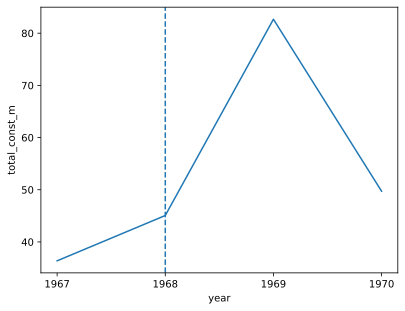

In [677]:
sns.lineplot(
  x='year', y='total_const_m',
  data=drc_80s_df,
)
# plt.axvline(1960, ls='--')
plt.axvline(y0, ls='--')
# plt.xlim([1978,1984])
plt.xticks([y0-1,y0,y1,y1+1])
plt.show()

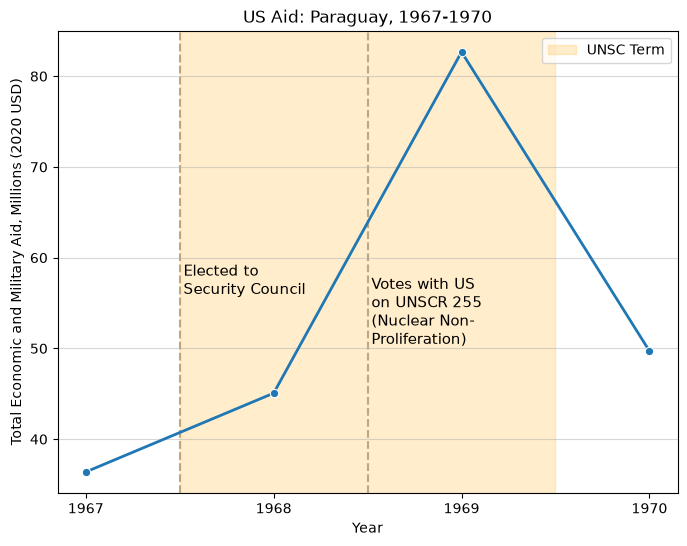

In [790]:
plt.figure(figsize=(8,6));
plt.grid(axis='y', alpha=0.5);
sns.lineplot(
  x='year', y='total_const_m',
  # hue='Assistance Category',
  data=drc_80s_df,
  marker='o',
  zorder=10,
  linewidth=2,
)
plt.title("US Aid: Paraguay, 1967-1970")
# plt.xlim(1989, 1992)
plt.xticks([y0-1,y0,y1,y1+1]);
plt.axvline(x=y0-0.5, linestyle='--', color='darkgray', zorder=1);
plt.axvline(x=y1-0.5, linestyle='--', color='darkgray', zorder=1);
plt.axvspan(y0-0.5, y1+0.5, color="orange", alpha=0.2, label="UNSC Term");
plt.xlabel('Year');
plt.ylabel('Total Economic and Military Aid, Millions (2020 USD)');
plt.text(
  x=y0-0.48, y=56, s='Elected to\nSecurity Council', zorder=15,
  size=11,
);
plt.text(
  x=y1-0.48, y=50.5, s='Votes with US\non UNSCR 255\n(Nuclear Non-\nProliferation)', zorder=15,
  size=11,
);
plt.legend();
# plt.ylim(bottom=0);
plt.show()

## 1968: Algeria

In [688]:
alg_df = aid_df[aid_df['country'].str.contains('Algeria')].copy()

In [689]:
alg_total_df = alg_df.groupby('year')['total_const_m'].sum().to_frame().reset_index()
# drc_total_df.plot()

In [692]:
alg_total_df

,year,total_const_m
0,1956,0.007541
1,1957,5.818182
2,1958,0.705716
3,1959,4.864489
4,1960,4.112406
5,1961,15.561570
6,1962,64.300067
7,1963,459.960292
8,1964,296.078431
9,1965,97.043702


In [690]:
alg_60s_df = alg_total_df[(alg_total_df['year'] >= lower) & (alg_total_df['year'] <= upper)].copy()

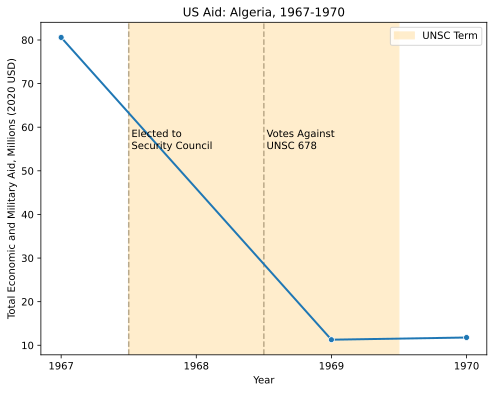

In [691]:
plt.figure(figsize=(8,6))
sns.lineplot(
  x='year', y='total_const_m',
  # hue='Assistance Category',
  data=alg_60s_df,
  marker='o',
  zorder=10,
  linewidth=2,
)
plt.title("US Aid: Algeria, 1967-1970")
# plt.xlim(1989, 1992)
plt.xticks([y0-1,y0,y1,y1+1]);
plt.axvline(x=y0-0.5, linestyle='--', color='darkgray', zorder=1);
plt.axvline(x=y1-0.5, linestyle='--', color='darkgray', zorder=1);
plt.axvspan(y0-0.5, y1+0.5, color="orange", alpha=0.2, label="UNSC Term");
plt.xlabel('Year');
plt.ylabel('Total Economic and Military Aid, Millions (2020 USD)');
plt.text(x=y0-0.48, y=55, s='Elected to\nSecurity Council', zorder=15);
plt.text(x=y1-0.48, y=55, s='Votes Against\nUNSC 678', zorder=15);
plt.legend();
plt.show()